In [69]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from matplotlib.ticker import FuncFormatter

from sklearn import svm

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from datetime import datetime

import os
import sys

from configparser import ConfigParser
from pathlib import Path

# Set the working directory to the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src" / "insurance_pricing").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)

# Make your source package importable
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from Insurance_pricing.data import Find_N_datasets, inspect_dataset
from Insurance_pricing.cleaning import clean_types, clean_dates

In [70]:
print(os.getcwd())

c:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing


In [71]:
paths = Find_N_datasets(2)
motor = pd.read_csv(paths[0], sep=";")
claims = pd.read_csv(paths[1], sep=";")

motor_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Raw\Motor.csv
claims_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Raw\Claims.csv


In [72]:
inspect_dataset(claims) #inspection shows there's no null and/or missing elements in the dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7366 entries, 0 to 7365
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   7366 non-null   int64  
 1   Cost_claims_year     7366 non-null   float64
 2   Cost_claims_by_type  7366 non-null   float64
 3   Claims_type          7366 non-null   object 
dtypes: float64(2), int64(1), object(1)
memory usage: 230.3+ KB

Info of the dataset:
None

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
    

Checking the missing values:
ID                     0
Cost_claims_year       0
Cost_claims_by_type    0
Claims_type            0
dtype: int64

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
   

In [73]:
inspect_dataset(motor)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105555 entries, 0 to 105554
Data columns (total 30 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    105555 non-null  int64  
 1   Date_start_contract   105555 non-null  object 
 2   Date_last_renewal     105555 non-null  object 
 3   Date_next_renewal     105555 non-null  object 
 4   Date_birth            105555 non-null  object 
 5   Date_driving_licence  105555 non-null  object 
 6   Distribution_channel  105555 non-null  int64  
 7   Seniority             105555 non-null  int64  
 8   Policies_in_force     105555 non-null  int64  
 9   Max_policies          105555 non-null  int64  
 10  Max_products          105555 non-null  int64  
 11  Lapse                 105555 non-null  int64  
 12  Date_lapse            35147 non-null   object 
 13  Payment               105555 non-null  int64  
 14  Premium               105555 non-null  float64
 15  

In [74]:
motor = clean_dates(motor)

## Columns of interest

the columns of interest are:

Date_lapse, Type_fuel, Length

### Imprefection Qualities

all the values that're non-null are missing. And thus must mbe

In [75]:
missing_cols = motor[['Date_lapse', 'Type_fuel', 'Length']].copy()
missing_cols

,Date_lapse,Type_fuel,Length
0,NaT,P,NaN
1,NaT,P,NaN
2,NaT,P,NaN
3,NaT,P,NaN
4,NaT,P,NaN
...,...,...,...
105550,NaT,D,4.740
105551,NaT,P,4.650
105552,NaT,P,3.495
105553,NaT,D,4.555


In [76]:
missing_cols['Type_fuel'].unique()

array(['P', 'D', nan], dtype=object)

In [77]:
# gives the proportion of rows with missing values
missing_rows = missing_cols.isna().any(axis=1).sum()
missing_rows/len(missing_cols) * 100

np.float64(69.85647292880489)

Nearly 70% of rows have missing values. This isn't something that can be solved through simple removal of erroneous entries

In [78]:
inspect_dataset(missing_cols)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105555 entries, 0 to 105554
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   Date_lapse  35147 non-null   datetime64[ns]
 1   Type_fuel   103791 non-null  object        
 2   Length      95226 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 2.4+ MB

Info of the dataset:
None

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
    

Checking the missing values:
Date_lapse    70408
Type_fuel      1764
Length        10329
dtype: int64

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
        
Stats for categorical columns:

       Type_fuel
count     103791
unique      

From this we know the number of missing values in fuel type isn't significant enough, 1.72%, to handle beyond dropping the offending rows.

In [79]:
# Create a copy of the motor dataset
motor_check = motor.copy()

# Get the IDs present in the claims dataset
claim_ids = claims["ID"].dropna().astype("string").str.strip()

# Check whether each motor ID appears in the claims dataset
motor_ids = motor_check["ID"].astype("string").str.strip()
motor_check["Claim_Made"] = motor_ids.isin(claim_ids)

# Identify rows where Date_lapse is missing
missing_lapse = motor_check["Date_lapse"].isna()

# Missing Date_lapse where a claim exists
missing_with_claim = motor_check[
    missing_lapse & motor_check["Claim_Made"]
]

# Missing Date_lapse where no matching claim was found
missing_without_claim = motor_check[
    missing_lapse & ~motor_check["Claim_Made"]
]

# Summarise the results
print(f"Total rows: {len(motor_check):,}")
print(f"Rows missing Date_lapse: {missing_lapse.sum():,}")
print(f"Missing Date_lapse with a claim: {len(missing_with_claim):,}")
print(f"Missing Date_lapse without a matching claim: {len(missing_without_claim):,}")

# Count unique IDs as well
print(
    "Unique IDs missing Date_lapse with a claim:",
    missing_with_claim["ID"].nunique()
)

Total rows: 105,555
Rows missing Date_lapse: 70,408
Missing Date_lapse with a claim: 6,270
Missing Date_lapse without a matching claim: 64,138
Unique IDs missing Date_lapse with a claim: 2921


At only 2.77% missingness in the date_lapse, we can simply remove the date_lapse from the dataset, to do this we can use a column called 'contrat_terminated' to outline those without a termination date, as it's likely.

In [80]:
claim_ids = claims["ID"].dropna().unique()

# Identify IDs with a missing Date_lapse and a claim
ids_to_drop = motor.loc[
    motor["Date_lapse"].isna() & motor["ID"].isin(claim_ids),
    "ID"
].unique()

# Drop ALL rows belonging to those IDs
motor = motor[~motor["ID"].isin(ids_to_drop)].copy()

# 1 means there's a recorded termination date, 0 means no such date exists
motor_check["Contract_Terminated"] = (
    motor_check["Date_lapse"].notna().astype(int)
)

In [81]:
analysis = clean_dates(motor.copy())
analysis = clean_types(analysis)

for col in missing_cols:
    analysis[f"{col}_missing"] = analysis[col].isna().astype(int) # Adds missingness indicator

In [90]:
analysis['Length_missing'].unique()

array([1, 0])

In [83]:
analysis[analysis['ID'] < 20].drop_duplicates('ID')

,ID,Date_start_contract,Date_last_renewal,Date_next_renewal,Date_birth,Date_driving_licence,Distribution_channel,Seniority,Policies_in_force,Max_policies,...,Power,Cylinder_capacity,Value_vehicle,N_doors,Type_fuel,Length,Weight,Date_lapse_missing,Type_fuel_missing,Length_missing
0,1,2015-11-05,2015-11-05,2016-11-05,1956-04-15,1976-03-20,0,4,1,2,...,80,599,7068.00,0,1.0,NaN,190,1,0,1
4,2,2017-09-26,2017-09-26,2018-09-26,1956-04-15,1976-03-20,0,4,2,2,...,80,599,7068.00,0,1.0,NaN,190,1,0,1
6,3,2013-11-29,2015-11-29,2016-11-29,1975-03-18,1995-07-10,0,15,1,2,...,85,1229,16030.00,5,1.0,3.999,1105,1,0,0
10,4,2016-10-21,2016-10-21,2017-10-21,1973-07-10,1993-07-05,0,3,1,2,...,6,74,1261.82,0,1.0,NaN,87,1,0,1
13,5,2017-05-12,2017-05-12,2018-05-12,1973-07-10,1993-07-05,0,3,2,2,...,6,244,3000.00,0,1.0,NaN,92,1,0,1
15,6,2006-05-29,2016-05-29,2017-05-29,1966-10-21,1990-09-10,0,13,1,2,...,87,1598,9927.00,4,1.0,4.250,1055,1,0,0
18,7,2015-02-11,2016-02-11,2017-02-11,1946-05-14,2000-03-24,1,3,1,1,...,109,1396,16550.00,5,1.0,4.245,1168,0,0,0
19,8,2001-05-28,2016-05-28,2017-05-28,1941-05-11,1962-08-01,0,18,1,2,...,130,1984,27330.00,4,1.0,4.547,1310,1,0,0
22,9,2013-10-24,2016-10-24,2017-10-24,1949-10-22,1995-05-17,1,6,1,3,...,65,1870,13140.00,5,0.0,4.129,1125,0,0,0
24,10,2017-01-13,2017-01-13,2018-01-13,1949-10-22,1995-05-17,1,6,3,3,...,65,1560,24850.00,5,0.0,4.590,1530,1,0,0


In [84]:
Today = pd.Timestamp.today().normalize()
Year_const = 365.25

analysis['Policy_Age'] = (Today - analysis['Date_start_contract']).dt.days / Year_const
analysis['Licence_Age'] = (Today - analysis['Date_driving_licence']).dt.days / Year_const
analysis['Policy_Maker_Age'] = (Today - analysis['Date_birth']).dt.days / Year_const
analysis['Lapse_Age'] = (Today - analysis['Date_lapse']).dt.days / Year_const

In [85]:
analysis.columns

Index(['ID', 'Date_start_contract', 'Date_last_renewal', 'Date_next_renewal',
       'Date_birth', 'Date_driving_licence', 'Distribution_channel',
       'Seniority', 'Policies_in_force', 'Max_policies', 'Max_products',
       'Lapse', 'Date_lapse', 'Payment', 'Premium', 'Cost_claims_year',
       'N_claims_year', 'N_claims_history', 'R_Claims_history', 'Type_risk',
       'Area', 'Second_driver', 'Year_matriculation', 'Power',
       'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Type_fuel', 'Length',
       'Weight', 'Date_lapse_missing', 'Type_fuel_missing', 'Length_missing',
       'Policy_Age', 'Licence_Age', 'Policy_Maker_Age', 'Lapse_Age'],
      dtype='object')

In [86]:
analysis['Policy_Age'].std()

np.float64(4.072015772479025)

In [87]:
analysis['Old_Policy'] = (
    analysis["Policy_Age"] >
    (analysis["Policy_Age"].median() + analysis["Policy_Age"].std())
).astype(int)

analysis['Old_Policy_Maker'] = (
    analysis["Policy_Maker_Age"] >
    (analysis["Policy_Maker_Age"].median() + analysis["Policy_Maker_Age"].std())
).astype(int)

analysis['Heavy_Vehical'] = (
    analysis["Weight"] >
    (analysis["Weight"].median() + analysis["Weight"].std())
).astype(int)

In [88]:
analysis[analysis['ID'] < 10].drop_duplicates(subset='ID')

,ID,Date_start_contract,Date_last_renewal,Date_next_renewal,Date_birth,Date_driving_licence,Distribution_channel,Seniority,Policies_in_force,Max_policies,...,Date_lapse_missing,Type_fuel_missing,Length_missing,Policy_Age,Licence_Age,Policy_Maker_Age,Lapse_Age,Old_Policy,Old_Policy_Maker,Heavy_Vehical
0,1,2015-11-05,2015-11-05,2016-11-05,1956-04-15,1976-03-20,0,4,1,2,...,1,0,1,10.984257,50.611910,70.540726,NaN,0,1,0
4,2,2017-09-26,2017-09-26,2018-09-26,1956-04-15,1976-03-20,0,4,2,2,...,1,0,1,9.092402,50.611910,70.540726,NaN,0,1,0
6,3,2013-11-29,2015-11-29,2016-11-29,1975-03-18,1995-07-10,0,15,1,2,...,1,0,0,12.917180,31.307324,51.619439,NaN,0,0,0
10,4,2016-10-21,2016-10-21,2017-10-21,1973-07-10,1993-07-05,0,3,1,2,...,1,0,1,10.023272,33.319644,53.305955,NaN,0,0,0
13,5,2017-05-12,2017-05-12,2018-05-12,1973-07-10,1993-07-05,0,3,2,2,...,1,0,1,9.467488,33.319644,53.305955,NaN,0,0,0
15,6,2006-05-29,2016-05-29,2017-05-29,1966-10-21,1990-09-10,0,13,1,2,...,1,0,0,20.421629,36.136893,60.024641,NaN,1,0,0
18,7,2015-02-11,2016-02-11,2017-02-11,1946-05-14,2000-03-24,1,3,1,1,...,0,0,0,11.715264,26.600958,80.462697,9.713895,0,1,0
19,8,2001-05-28,2016-05-28,2017-05-28,1941-05-11,1962-08-01,0,18,1,2,...,1,0,0,25.423682,64.246407,85.470226,NaN,1,1,0
22,9,2013-10-24,2016-10-24,2017-10-24,1949-10-22,1995-05-17,1,6,1,3,...,0,0,0,13.015743,31.455168,77.021218,9.015743,0,1,0


In [93]:
Length_imputation = analysis[
    [
        'ID', 'Distribution_channel', 'Seniority', 'Policies_in_force', 
        'Max_policies', 'Max_products', 'Lapse', 'Date_lapse',
        'Payment', 'Premium', 'Cost_claims_year', 'N_claims_year',
        'N_claims_history', 'R_Claims_history', 'Type_risk', 'Area',
        'Second_driver', 'Year_matriculation', 'Power', 'Cylinder_capacity',
        'Value_vehicle', 'N_doors', 'Type_fuel', 'Length', 'Weight', 'Date_lapse_missing',
       'Type_fuel_missing', 'Length_missing', 'Policy_Age', 'Licence_Age',
       'Policy_Maker_Age', 'Lapse_Age', 'Old_Policy', 'Heavy_Vehical', 'Old_Policy_Maker'
    ]
].copy()
#Length_imputation.dropna(subset=["Length","Type_fuel"], inplace=True)
Length_imputation.head()

,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Date_lapse,Payment,Premium,...,Date_lapse_missing,Type_fuel_missing,Length_missing,Policy_Age,Licence_Age,Policy_Maker_Age,Lapse_Age,Old_Policy,Heavy_Vehical,Old_Policy_Maker
0,1,0,4,1,2,1,0,NaT,0,222.52,...,1,0,1,10.984257,50.61191,70.540726,NaN,0,0,1
1,1,0,4,1,2,1,0,NaT,0,213.78,...,1,0,1,10.984257,50.61191,70.540726,NaN,0,0,1
2,1,0,4,2,2,1,0,NaT,0,214.84,...,1,0,1,10.984257,50.61191,70.540726,NaN,0,0,1
3,1,0,4,2,2,1,0,NaT,0,216.99,...,1,0,1,10.984257,50.61191,70.540726,NaN,0,0,1
4,2,0,4,2,2,1,0,NaT,1,213.70,...,1,0,1,9.092402,50.61191,70.540726,NaN,0,0,1


In [96]:
Length_imputation['Policies_in_force'].unique(), analysis['Policies_in_force'].unique()

(array([ 1,  2,  3,  4,  5,  8,  6,  9, 10, 14,  7, 12, 11, 13, 15, 17, 16]),
 array([ 1,  2,  3,  4,  5,  8,  6,  9, 10, 14,  7, 12, 11, 13, 15, 17, 16]))

In [97]:
col = [
    'Type_risk',
    'Type_fuel', 
    'Date_lapse_missing',
    'N_doors',
    'Second_driver',
    'Old_Policy',
    'Lapse',
    'Distribution_channel',
    'Old_Policy', 
    'Heavy_Vehical',
    'Old_Policy_Maker',
    'Area'
]


for col in cols:
    print(f"\n{col}\n")
    table = pd.crosstab(
        Length_imputation['Length_missing'],
        Length_imputation[col]
    )
    print(f"{table}\n")
    chi2, p, dof, ex = stats.chi2_contingency(table,)
    print(f"p-value: {p}") 


Type_risk

Type_risk          1      2      3    4
Length_missing                         
0                  2  12097  77167   23
1               8226    252    690  828

p-value: 0.0

Date_lapse_missing

Date_lapse_missing      0      1
Length_missing                  
0                   31818  57471
1                    3329   6667

p-value: 3.995059733680804e-06

N_doors

N_doors            0     2      3      4      5    6
Length_missing                                      
0                 25  2859  13460  13153  59262  530
1               8975   147    162    156    554    2

p-value: 0.0

Second_driver

Second_driver       0      1
Length_missing              
0               77293  11996
1                9918     78

p-value: 8.851488636431121e-295

Old_Policy

Old_Policy          0      1
Length_missing              
0               73173  16116
1                8357   1639

p-value: 4.594668199441279e-05

Lapse

Lapse               0      1     2    3   4  5  6  7
Length

given these values, a MCAR analysis seems to not be useful. This is as the p values are so exceptionally small. We should likely investigate how the relationship be behaves, looking at proportions of missingness across different groups and how it develops with age through plots.

In [20]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

encoded = encoder.fit_transform(Length_imputation[["Type_risk"]])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(["Type_risk"]),
    index=Length_imputation.index
)

Length_imputation = pd.concat([Length_imputation, encoded_df], axis=1)
Length_imputation.drop(columns=["Type_risk"], inplace=True)
Length_imputation.head()

,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Date_lapse,Payment,Premium,...,Type_fuel_missing,Length_missing,Policy_Age,Licence_Age,Policy_Maker_Age,Lapse_Age,Type_risk_1,Type_risk_2,Type_risk_3,Type_risk_4
6,3,0,15,1,2,1,0,NaT,0,380.20,...,0,0,12.914442,31.304586,51.616701,NaN,0.0,0.0,1.0,0.0
7,3,0,15,1,2,1,0,NaT,0,393.50,...,0,0,12.914442,31.304586,51.616701,NaN,0.0,0.0,1.0,0.0
8,3,0,15,1,2,1,0,NaT,0,393.50,...,0,0,12.914442,31.304586,51.616701,NaN,0.0,0.0,1.0,0.0
9,3,0,15,1,2,1,0,NaT,0,395.47,...,0,0,12.914442,31.304586,51.616701,NaN,0.0,0.0,1.0,0.0
15,6,0,13,1,2,2,0,NaT,0,250.52,...,0,0,20.418891,36.134155,60.021903,NaN,0.0,0.0,1.0,0.0


In [21]:
Length_imputation.rename(columns={"Type_risk_1":"Is_Motorbike",
                                  "Type_risk_2":"Is_Van",
                                  "Type_risk_3":"Is_Passenger_Car",
                                  "Type_risk_4":"Is_Agricultural"},inplace=True)
Length_imputation.head()

,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Date_lapse,Payment,Premium,...,Type_fuel_missing,Length_missing,Policy_Age,Licence_Age,Policy_Maker_Age,Lapse_Age,Is_Motorbike,Is_Van,Is_Passenger_Car,Is_Agricultural
6,3,0,15,1,2,1,0,NaT,0,380.20,...,0,0,12.914442,31.304586,51.616701,NaN,0.0,0.0,1.0,0.0
7,3,0,15,1,2,1,0,NaT,0,393.50,...,0,0,12.914442,31.304586,51.616701,NaN,0.0,0.0,1.0,0.0
8,3,0,15,1,2,1,0,NaT,0,393.50,...,0,0,12.914442,31.304586,51.616701,NaN,0.0,0.0,1.0,0.0
9,3,0,15,1,2,1,0,NaT,0,395.47,...,0,0,12.914442,31.304586,51.616701,NaN,0.0,0.0,1.0,0.0
15,6,0,13,1,2,2,0,NaT,0,250.52,...,0,0,20.418891,36.134155,60.021903,NaN,0.0,0.0,1.0,0.0


In [30]:
Length_imputation['Length_missing']

6         0
7         0
8         0
9         0
15        0
         ..
105550    0
105551    0
105552    0
105553    0
105554    0
Name: Length_missing, Length: 89289, dtype: int64

In [24]:
# Define the target and predictor columns
target = "Length"

features = [
    "Power",
    "Cylinder_capacity",
    "Is_Van",
    "Is_Passenger_Car",
    "Is_Agricultural",
    "Value_vehicle",
    "N_doors",
    "Weight",
    "Second_driver"
]

Learning_curve = []

# Define the target and predictors
target = "Length"

# Keep rows where Length is known
known = Length_imputation.dropna(subset=[target]).copy()

X = known[features]
y = known[target]

for i in range(0, 9):
    # Split into training and testing data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size = 0.1 + float(f"0.{i}"),
        random_state=42
    )

    temp = []

    for j in range(5, 100, 5):
        # Build the RFR pipeline
        rfr = Pipeline([
            (("imputer", SimpleImputer(strategy="median"))),
            ("model", RandomForestRegressor(n_estimators=j,
            random_state=42,
            n_jobs= 13 # Based on the num of cores
            ))
        ])

        # Train and evaluate the model
        rfr.fit(X_train, y_train)

        predictions = rfr.predict(X_test)

        # Cross validation scoring
        scores = cross_val_score(rfr, X_test, y_test, cv=5) # We can just avoid the hyperparameter stuff for now...

        temp.append({
            "Mean_CVS_score": scores.mean(),
            "Prediction_Scores": [r2_score(y_test, predictions), mean_absolute_error(y_test, predictions), np.sqrt(mean_squared_error(y_test, predictions))],
            "Num_of_estimators": j
        })

    Learning_curve.append({
        "Run_of_interest": temp,
        "Test_train_split": 0.1 + float(f"0.{i}")
    })

KeyboardInterrupt: 

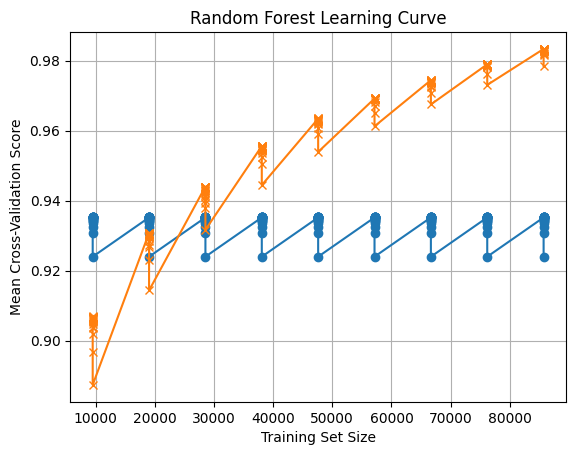

In [ ]:
train_sizes = [result["Train_size"] for result in Learning_curve]
mean_scores = [result["Mean_CVS_score"] for result in Learning_curve]
predicted_scores = [result["Prediction_Scores"][0] for result in Learning_curve]

plt.plot(train_sizes, mean_scores, marker="o")
plt.plot(train_sizes, predicted_scores, marker="x")
plt.xlabel("Training Set Size")
plt.ylabel("Mean Cross-Validation Score")
plt.title("Random Forest Learning Curve")
plt.grid(True)
plt.show()

In [ ]:
records = sorted(Learning_curve, key=lambda x: x["Train_size"])

train_sizes = [r["Train_size"] for r in records]
mean_scores = [r["Mean_CVS_score"] for r in records]
std_scores = [np.std(r["CV_scores"]) for r in records]

plt.errorbar(
    train_sizes,
    mean_scores,
    yerr=std_scores,
    marker="o",
    capsize=3
)

plt.xlabel("Training Set Size")
plt.ylabel("Mean Cross-Validation R²") 
plt.title("Random Forest Learning Curve")
plt.grid(True)
plt.show()

KeyError: 'CV_scores'

In [ ]:
# Calculate permutation importance
importance = permutation_importance(
    rfr,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

# Display features in order of predictive importance
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)


In [ ]:
#Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Payment,Premium,Cost_claims_year,Type_risk,Area